In [17]:
import agama, numpy
from astropy import units as u 
from astropy import constants as cnst
import h5py 
from matplotlib import pyplot as plt 
from matplotlib.gridspec import GridSpec

In [2]:
def print_tree(group, indent=0):
    pad = "    " * indent
    for key, item in group.items():
        if isinstance(item, h5py.Group):          # public name; avoid h5py._hl.group.Group
            print(f"{pad}{key}/   ({len(item.attrs)} attrs)")
            print_tree(item, indent + 1)
        else:
            print(f"{pad}{key}   {item.shape} {item.dtype}")

In [3]:
# open the output file and analyze it 
myfile=h5py.File("ferrers_bar.h5",'r')
print_tree(myfile)

nbody_200/   (28 attrs)
    initial_conditions   (200, 6) float64
    mass   (200,) float64
    potential_energy_external   (20001, 200) float32
    potential_energy_internal   (20001, 200) float32
    time   (20001,) float64
    trajectories   (20001, 200, 6) float32
schwarzschild/   (30 attrs)
    gridr   (11,) float64
    ics   (2000, 6) float64
    inputs/   (0 attrs)
        bar_ini   () object
        ext_ini   () object
    mass_model   (191,) float64
    mass_true   (191,) float64
    matrix_data_density   (2000, 191) float32
    orbit_times   (2000,) float64
    potential/   (1 attrs)
        bar/   (5 attrs)
        halo/   (3 attrs)
        thick_disk/   (4 attrs)
        thin_disk/   (4 attrs)
    sigma   (191,) float64
    trajectories/   (0 attrs)
        data   (3263970, 6) float64
        offsets   (2001,) int64
        time   (3263970,) float64
    weights   (2000,) float64


### Analysis and checks 

- Total energy conservation 
- animation
- Jacobi energy of each star ?
- movement in E,L_z plane

In [14]:
group = "nbody_200"
mass = myfile[group]["mass"][:]
potential_energy_external = mass*myfile[group]["potential_energy_external"][:]
potential_energy_internal = 0.5*mass*myfile[group]["potential_energy_internal"][:]
kinetic_energy = (1/2)*mass*numpy.sum(myfile[group]["trajectories"][:,:,3:6]**2,axis=2)
timesteps = myfile[group]["time"][:]

In [15]:
E_total = potential_energy_external + potential_energy_internal + kinetic_energy
total_energy = numpy.sum(E_total,axis=1)
eDrift = numpy.abs((total_energy - total_energy[0]) / total_energy[0])

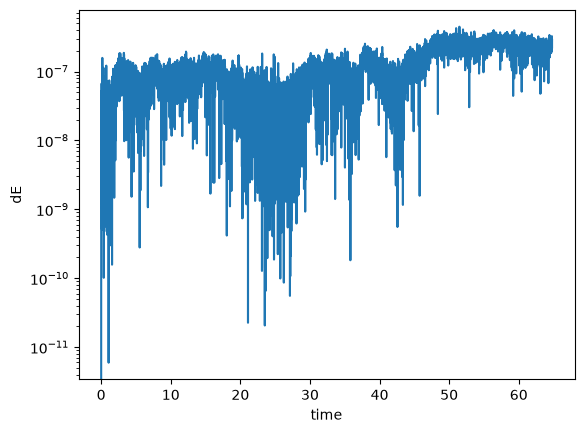

In [16]:
fig,axis=plt.subplots(1,1)
axis.plot(timesteps,eDrift)
axis.set(xlabel="time",ylabel="dE",yscale="log")
fig.savefig(f"test_total_energy_conservation_{group}.png",dpi=300)

In [ ]:
thick_disk=dict(myfile['schwarzschild']['potential']['thick_disk'].attrs)
thin_disk=dict(myfile['schwarzschild']['potential']['thin_disk'].attrs)
halo=dict(myfile['schwarzschild']['potential']['halo'].attrs)

In [149]:
if ("disk" in "thick_disk"):
    print("no")

no


In [170]:
# extract the discks
def extract_disks(schwarzschild_potential):
    disks = []
    for key in schwarzschild_potential.keys():
        if "disk" in key:
            disks.append(dict(schwarzschild_potential[key].attrs))
    return disks
disks = extract_disks(myfile['schwarzschild']['potential'])
pdisks=agama.Potential(*disks)

In [ ]:
npoints=20
xmin,xmax=-2,2
ymin,ymax=-2,2
xs=numpy.linspace(xmin,xmax,npoints);ys=numpy.linspace(ymin,ymax,npoints);
XS,YS   =numpy.meshgrid(xs,ys)
XY          =numpy.column_stack((XS.flatten(),YS.flatten()))
pdensity    =pdisks.projectedDensity(XY)

In [ ]:
# get data from the file
trajectories    =   myfile[group]['trajectories']
timestamps      =   myfile[group]['time'] * myfile[group].attrs['unitT'] * u.s * u.kpc/u.km
timestamps      =   timestamps.to(u.Myr).value
nbody           =   myfile[group]['mass'].shape[0]

In [178]:
height

np.float64(2.9803149606299213)

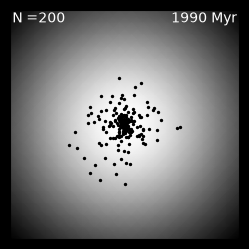

In [179]:
width=(150.9*u.mm).to(u.imperial.inch).value
height=(75.7*u.mm).to(u.imperial.inch).value

timeindex = 19900;xindex=0;yindex=1
str_time = "{:.0f} Myr".format(timestamps[timeindex])
# UNIVERSAL ACROSS ALL FRAMES 
fig=plt.figure(figsize=(width,height),facecolor="k")
axes=fig.add_subplot(111)
axes.text(0.01,0.99,r"N ={:d}".format(nbody),va="top",ha="left",transform=axes.transAxes,color="white")
axes.set(xlim=[xmin,xmax],ylim=[xmin,xmax],aspect="equal",xticks=[],yticks=[])
axes.pcolormesh(XS,YS,numpy.reshape(pdensity,XS.shape),cmap="grey",shading="gouraud")
# FRAME SPECIFIC 
scat=axes.scatter(trajectories[timeindex,:,xindex],trajectories[timeindex,:,yindex],s=2,color="k")
txt=axes.text(0.99,0.99,str_time,va="top",ha="right",transform=axes.transAxes,color="white")
fig.savefig("example_frame_{:06d}.png".format(timeindex),dpi=300)